# Бейзлайн

Задача: для каждого маршрута `route_id` спрогнозировать `target_1h` на 8 следующих точек
с шагом 30 минут после конца train. Строки теста перечислены в `test_solo_track.parquet`.

Посылка - CSV `sample_submission.csv` с колонками `id,y_pred`: ровно одна строка на каждый `id` из теста.

Метрика - **WAPE + |Relative Bias|**, меньше - лучше:

$$\text{score} = \frac{\sum |\hat y - y|}{\sum y} + \left|\frac{\sum \hat y}{\sum y} - 1\right|$$

Если окружение ещё не настроено:

```python
# %pip install pandas pyarrow numpy matplotlib scikit-learn jupyter ipykernel
```

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [9]:
from pathlib import Path

# Определяем корень проекта
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data" / "raw").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

# Пути к данным
DATA_DIR = PROJECT_ROOT / "data" / "raw"

TRAIN_PATH = DATA_DIR / "train_solo_track.parquet"
TEST_PATH = DATA_DIR / "test_solo_track.parquet"

# Путь сохранения результата
SUBMISSION_PATH = PROJECT_ROOT / "submissions" / "baseline_submission.csv"
SUBMISSION_PATH.parent.mkdir(parents=True, exist_ok=True)

# Проверяем наличие файлов
print("Project root:", PROJECT_ROOT)
print("Train exists:", TRAIN_PATH.exists())
print("Test exists:", TEST_PATH.exists())

assert TRAIN_PATH.exists(), f"Train not found: {TRAIN_PATH}"
assert TEST_PATH.exists(), f"Test not found: {TEST_PATH}"

Project root: c:\Users\Dell-BooK\OneDrive\Desktop\RWB_hack
Train exists: True
Test exists: True


## Загрузка данных

In [13]:
train_df = pd.read_parquet(TRAIN_PATH)
test_df = pd.read_parquet(TEST_PATH)

train_df["timestamp"] = pd.to_datetime(train_df["timestamp"])
test_df["timestamp"] = pd.to_datetime(test_df["timestamp"])

train_df = train_df.sort_values(["route_id", "timestamp"]).reset_index(drop=True)
test_df = test_df.sort_values(["route_id", "timestamp"]).reset_index(drop=True)

print("train shape:", train_df.shape)
print("test shape:", test_df.shape)

train shape: (4630000, 9)
test shape: (8000, 3)


In [14]:
display(train_df.head())
display(test_df.head())

,route_id,timestamp,status_1,status_2,status_3,status_4,status_5,status_6,target_1h
0,0,2025-07-28 00:00:00,13,13,7,58053,136443,97,87359
1,0,2025-07-28 00:30:00,6,18,13,58867,134643,95,182291
2,0,2025-07-28 01:00:00,7,8,27,54848,135534,96,271432
3,0,2025-07-28 01:30:00,7,8,5,53086,136497,100,169736
4,0,2025-07-28 02:00:00,1,6,0,57561,135314,101,38880


,id,route_id,timestamp
0,3920,0,2025-11-01 11:00:00
1,3921,0,2025-11-01 11:30:00
2,3922,0,2025-11-01 12:00:00
3,3923,0,2025-11-01 12:30:00
4,3924,0,2025-11-01 13:00:00


In [15]:
print("Train date range:", train_df["timestamp"].min(), "->", train_df["timestamp"].max())
print("Test date range:", test_df["timestamp"].min(), "->", test_df["timestamp"].max())
print("Train routes:", train_df["route_id"].nunique())
print("Test routes:", test_df["route_id"].nunique())
print("Test points per route:", test_df.groupby("route_id").size().unique())

Train date range: 2025-07-28 00:00:00 -> 2025-11-01 10:30:00
Test date range: 2025-11-01 11:00:00 -> 2025-11-01 14:30:00
Train routes: 1000
Test routes: 1000
Test points per route: [8]


## EDA train-данных

In [16]:
overview = pd.DataFrame({
    "dtype": train_df.dtypes.astype(str),
    "missing_cnt": train_df.isna().sum(),
    "missing_pct": (train_df.isna().mean() * 100).round(4),
    "n_unique": train_df.nunique(dropna=False),
})
overview

,dtype,missing_cnt,missing_pct,n_unique
route_id,int64,0,0.0,1000
timestamp,datetime64[ns],0,0.0,4630
status_1,int64,0,0.0,272
status_2,int64,0,0.0,243
status_3,int64,0,0.0,260
status_4,int64,0,0.0,315655
status_5,int64,0,0.0,1463128
status_6,int64,0,0.0,82051
target_1h,int64,0,0.0,692648


In [17]:
status_cols = sorted(col for col in train_df.columns if col.startswith("status_"))
print("Status columns:", status_cols)
print("Target column:", TARGET_COL)

Status columns: ['status_1', 'status_2', 'status_3', 'status_4', 'status_5', 'status_6']
Target column: target_1h


## Распределения

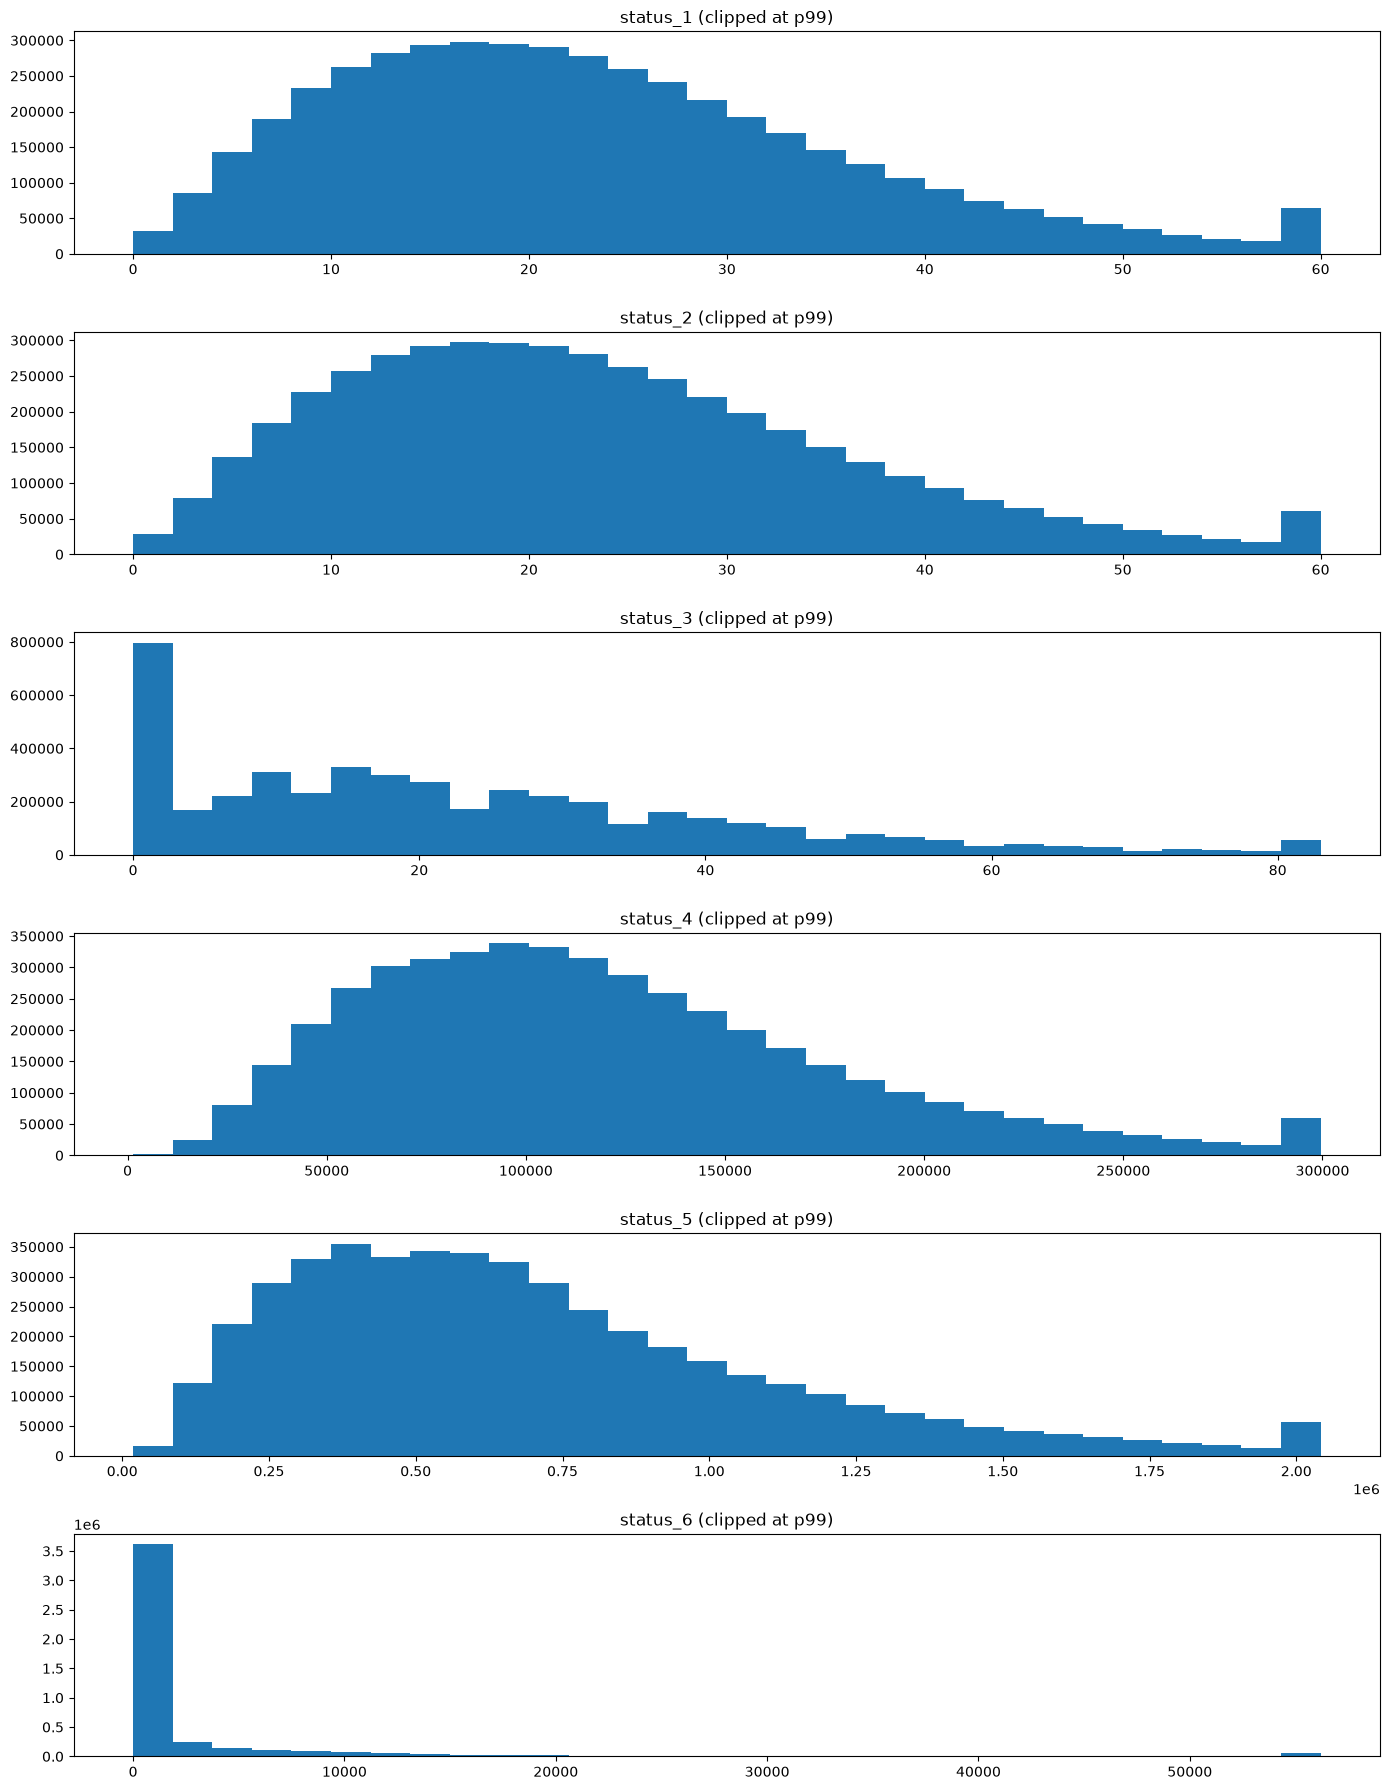

In [19]:
import numpy as np
fig, axes = plt.subplots(len(status_cols), 1, figsize=(14, 3 * len(status_cols)))

for ax, col in zip(np.atleast_1d(axes), status_cols, strict=True):
    ax.hist(train_df[col].clip(upper=train_df[col].quantile(0.99)), bins=30)
    ax.set_title(f"{col} (clipped at p99)")

plt.tight_layout()
plt.show()

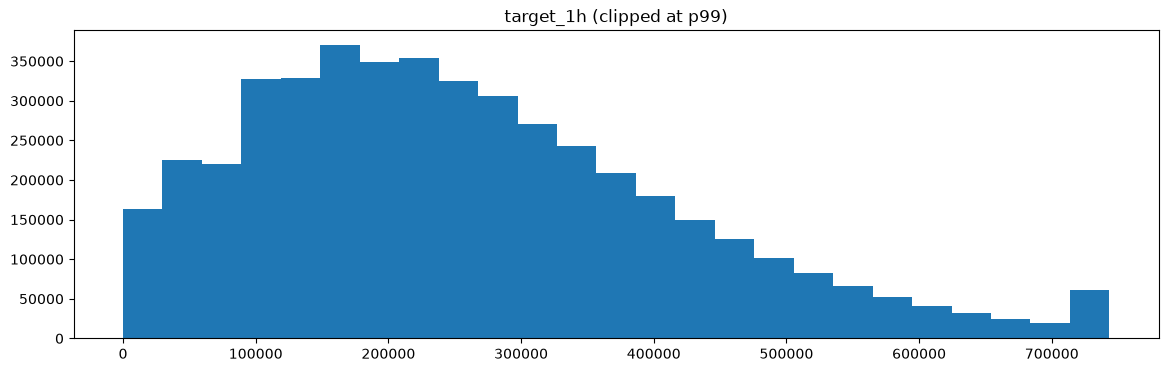

In [20]:
plt.figure(figsize=(14, 4))
plt.hist(train_df[TARGET_COL].clip(upper=train_df[TARGET_COL].quantile(0.99)), bins=25)
plt.title(f"{TARGET_COL} (clipped at p99)")
plt.show()

## Будущие таргеты

Для каждой строки train добавляем значения таргета через 1, 2, ... шагов вперёд по тому же маршруту.
Модель по текущему состоянию маршрута сразу предсказывает все шаги горизонта.

In [21]:
route_group = train_df.groupby("route_id", sort=False)

for step in range(1, FORECAST_POINTS + 1):
    train_df[f"target_step_{step}"] = route_group[TARGET_COL].shift(-step)

train_df[["route_id", "timestamp", TARGET_COL] + FUTURE_TARGET_COLS].head(10)

,route_id,timestamp,target_1h,target_step_1,target_step_2,target_step_3,target_step_4,target_step_5,target_step_6,target_step_7,target_step_8
0,0,2025-07-28 00:00:00,87359,182291.0,271432.0,169736.0,38880.0,134137.0,134137.0,77760.0,77760.0
1,0,2025-07-28 00:30:00,182291,271432.0,169736.0,38880.0,134137.0,134137.0,77760.0,77760.0,76829.0
2,0,2025-07-28 01:00:00,271432,169736.0,38880.0,134137.0,134137.0,77760.0,77760.0,76829.0,193469.0
3,0,2025-07-28 01:30:00,169736,38880.0,134137.0,134137.0,77760.0,77760.0,76829.0,193469.0,194401.0
4,0,2025-07-28 02:00:00,38880,134137.0,134137.0,77760.0,77760.0,76829.0,193469.0,194401.0,99590.0
5,0,2025-07-28 02:30:00,134137,134137.0,77760.0,77760.0,76829.0,193469.0,194401.0,99590.0,138470.0
6,0,2025-07-28 03:00:00,134137,77760.0,77760.0,76829.0,193469.0,194401.0,99590.0,138470.0,116641.0
7,0,2025-07-28 03:30:00,77760,77760.0,76829.0,193469.0,194401.0,99590.0,138470.0,116641.0,38880.0
8,0,2025-07-28 04:00:00,77760,76829.0,193469.0,194401.0,99590.0,138470.0,116641.0,38880.0,38880.0
9,0,2025-07-28 04:30:00,76829,193469.0,194401.0,99590.0,138470.0,116641.0,38880.0,38880.0,77760.0


In [22]:
supervised_df = train_df.dropna(subset=FUTURE_TARGET_COLS).copy()
print("Rows with future targets:", supervised_df.shape)

Rows with future targets: (4622000, 17)


## Корреляции

In [6]:
corr_cols = status_cols + FUTURE_TARGET_COLS
corr = supervised_df[corr_cols].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=90)
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax)
ax.set_title("Correlations on supervised train")
plt.show()

NameError: name 'status_cols' is not defined

## Подготовка train и test

In [5]:
feature_cols = [col for col in train_df.columns if col not in {TARGET_COL, "timestamp", "id", *FUTURE_TARGET_COLS}]
print("Feature columns:", feature_cols)

NameError: name 'train_df' is not defined

In [4]:
train_model_df = supervised_df[feature_cols + ["timestamp"] + FUTURE_TARGET_COLS].copy()
train_model_df = train_model_df.rename(columns={"timestamp": "source_timestamp"})

train_ts_max = train_model_df["source_timestamp"].max()
train_window_start = train_ts_max - pd.Timedelta(days=TRAIN_DAYS)
train_model_df = train_model_df[train_model_df["source_timestamp"] >= train_window_start].copy()

print("Recent train rows:", train_model_df.shape)

NameError: name 'supervised_df' is not defined

In [26]:
# прогноз строим от последнего известного состояния каждого маршрута
test_model_df = train_df.groupby("route_id", sort=False).tail(1).copy()
assert test_model_df["route_id"].nunique() == test_df["route_id"].nunique()

print("Inference rows:", test_model_df.shape)

Inference rows: (1000, 17)


## Time-based split

In [3]:
train_model_df = train_model_df.sort_values("source_timestamp").copy()
split_point = train_model_df["source_timestamp"].quantile(0.8)

fit_df = train_model_df[train_model_df["source_timestamp"] <= split_point].copy()
valid_df = train_model_df[train_model_df["source_timestamp"] > split_point].copy()

if len(fit_df) > MAX_TRAIN_ROWS:
    fit_df = fit_df.sample(MAX_TRAIN_ROWS, random_state=RANDOM_STATE)

print("Fit rows:", fit_df.shape)
print("Valid rows:", valid_df.shape)

NameError: name 'train_model_df' is not defined

In [2]:
X_fit = fit_df[feature_cols]
y_fit = fit_df[FUTURE_TARGET_COLS]

X_valid = valid_df[feature_cols]
y_valid = valid_df[FUTURE_TARGET_COLS]

X_test = test_model_df[feature_cols]

NameError: name 'fit_df' is not defined

## Линейный baseline

In [29]:
categorical_features = [col for col in feature_cols if col.endswith("_id")]
numeric_features = [col for col in feature_cols if col not in categorical_features]

print("Categorical features:", categorical_features)
print("Numeric features:", numeric_features)

Categorical features: ['route_id']
Numeric features: ['status_1', 'status_2', 'status_3', 'status_4', 'status_5', 'status_6']


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline(steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]),
            numeric_features,
        ),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

model = Pipeline(steps=[("preprocessor", preprocessor), ("regressor", Ridge(alpha=RIDGE_ALPHA))])

NameError: name 'numeric_features' is not defined

In [31]:
model.fit(X_fit, y_fit)

NameError: name 'model' is not defined

In [32]:
def predict(X: pd.DataFrame, index: pd.Index) -> pd.DataFrame:
    """Прогноз на все шаги горизонта; таргет неотрицательный, поэтому обрезаем снизу нулём."""
    return pd.DataFrame(model.predict(X), columns=FUTURE_TARGET_COLS, index=index).clip(lower=0)


fit_pred_df = predict(X_fit, fit_df.index)
valid_pred_df = predict(X_valid, valid_df.index)
test_pred_df = predict(X_test, test_model_df.index)

valid_pred_df.head()

NameError: name 'model' is not defined

## Метрика

Та же формула, что на платформе: WAPE + |Relative Bias|, меньше - лучше.
На платформе она считается по всем точкам посылки сразу (отдельно на Public и Private частях теста).

In [33]:
def wape_rbias(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """WAPE + |Relative Bias|, меньше - лучше."""
    y_true = np.asarray(y_true, dtype=float).ravel()
    y_pred = np.asarray(y_pred, dtype=float).ravel()
    wape = np.abs(y_pred - y_true).sum() / y_true.sum()
    rbias = np.abs(y_pred.sum() / y_true.sum() - 1)
    return wape + rbias


def report(name: str, y_true: pd.DataFrame, y_pred: pd.DataFrame) -> None:
    """Печатает общую метрику и метрику по каждому шагу горизонта."""
    by_step = pd.Series({col: wape_rbias(y_true[col], y_pred[col]) for col in FUTURE_TARGET_COLS})
    print(f"{name}: общая метрика = {wape_rbias(y_true, y_pred):.4f}")
    print("по горизонтам:")
    display(by_step.round(4).to_frame("wape_rbias").T)


report("Train (fit)", y_fit, fit_pred_df)
report("Валидация", y_valid, valid_pred_df)

NameError: name 'fit_pred_df' is not defined

## Конвертируем прогноз в формат посылки

In [34]:
test_pred_df["route_id"] = test_model_df["route_id"]
test_pred_df["last_timestamp"] = test_model_df["timestamp"]

# разворачиваем target_step_* в строки: шаг k -> время последнего факта + k * 30 минут
forecast_df = test_pred_df.melt(
    id_vars=["route_id", "last_timestamp"],
    value_vars=FUTURE_TARGET_COLS,
    var_name="step",
    value_name="y_pred",
)
forecast_df["step_num"] = forecast_df["step"].str.removeprefix("target_step_").astype(int)
forecast_df["timestamp"] = forecast_df["last_timestamp"] + forecast_df["step_num"] * STEP

submission = (
    test_df[["id", "route_id", "timestamp"]]
    .merge(forecast_df[["route_id", "timestamp", "y_pred"]], on=["route_id", "timestamp"], how="left")
    .sort_values("id")[["id", "y_pred"]]
    .reset_index(drop=True)
)
submission.head()

NameError: name 'test_pred_df' is not defined

In [35]:
# проверяем, что посылка в формате платформы: по одной строке на каждый id теста, без пропусков
assert len(submission) == len(test_df)
assert submission["id"].is_unique
assert set(submission["id"]) == set(test_df["id"])
assert submission["y_pred"].notna().all(), "для части точек теста не нашлось прогноза"

NameError: name 'submission' is not defined

## Выгрузка CSV

In [36]:
submission.to_csv(SUBMISSION_PATH, index=False)
print("submission saved to:", SUBMISSION_PATH)

NameError: name 'submission' is not defined

Файл `sample_submission.csv` (колонки `id,y_pred`) можно отправлять на платформу.

## Проверка активного Python Kernel

In [3]:
import sys
print(sys.executable)

c:\Users\Dell-BooK\OneDrive\Desktop\RWB_hack\.venv\Scripts\python.exe


## Загрузка обучающей и тестовой выборок

In [10]:
train = pd.read_parquet(TRAIN_PATH)
test = pd.read_parquet(TEST_PATH)

print("TRAIN shape:", train.shape)
print("TEST shape:", test.shape)

print("\nTRAIN columns:")
print(train.columns.tolist())

print("\nTEST columns:")
print(test.columns.tolist())

display(train.head())
display(test.head())

TRAIN shape: (4630000, 9)
TEST shape: (8000, 3)

TRAIN columns:
['route_id', 'timestamp', 'status_1', 'status_2', 'status_3', 'status_4', 'status_5', 'status_6', 'target_1h']

TEST columns:
['id', 'route_id', 'timestamp']


,route_id,timestamp,status_1,status_2,status_3,status_4,status_5,status_6,target_1h
0,471,2025-07-28 00:00:00,13,23,45,85645,491354,487,88655
1,471,2025-07-28 00:30:00,14,18,1,80049,494754,489,223929
2,471,2025-07-28 01:00:00,8,8,38,82616,490659,487,168519
3,471,2025-07-28 01:30:00,10,2,7,80506,489967,494,111380
4,471,2025-07-28 02:00:00,7,5,13,85992,479743,494,246046


,id,route_id,timestamp
0,0,471,2025-11-01 11:00:00
1,1,471,2025-11-01 11:30:00
2,2,471,2025-11-01 12:00:00
3,3,471,2025-11-01 12:30:00
4,4,471,2025-11-01 13:00:00


## Первичный аудит обучающей и тестовой выборок

In [11]:
# 1. Преобразование временных меток
train["timestamp"] = pd.to_datetime(train["timestamp"])
test["timestamp"] = pd.to_datetime(test["timestamp"])

# 2. Количество маршрутов
print("TRAIN ROUTES:", train["route_id"].nunique())
print("TEST ROUTES:", test["route_id"].nunique())

# 3. Временные диапазоны
print("\nTRAIN TIME RANGE:")
print(train["timestamp"].min(), "->", train["timestamp"].max())

print("\nTEST TIME RANGE:")
print(test["timestamp"].min(), "->", test["timestamp"].max())

# 4. Количество наблюдений на маршрут
print("\nTRAIN ROWS PER ROUTE:")
print(train.groupby("route_id").size().describe())

print("\nTEST ROWS PER ROUTE:")
print(test.groupby("route_id").size().value_counts().sort_index())

# 5. Пропущенные значения
print("\nMISSING VALUES IN TRAIN:")
print(train.isna().sum())

print("\nMISSING VALUES IN TEST:")
print(test.isna().sum())

# 6. Дубликаты
print("\nDUPLICATES:")
print(
    "Train:", train.duplicated(["route_id", "timestamp"]).sum()
)
print(
    "Test:", test.duplicated(["route_id", "timestamp"]).sum()
)
print(
    "Test duplicate IDs:", test["id"].duplicated().sum()
)

# 7. Распределение целевой переменной
print("\nTARGET STATISTICS:")
print(
    train["target_1h"].describe(
        percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]
    )
)

print("\nZERO TARGET SHARE:", train["target_1h"].eq(0).mean())
print("NEGATIVE TARGETS:", train["target_1h"].lt(0).sum())

# 8. Проверка интервалов между наблюдениями
train_sorted = train[
    ["route_id", "timestamp"]
].sort_values(["route_id", "timestamp"])

time_gaps = train_sorted.groupby(
    "route_id"
)["timestamp"].diff()

print("\nTRAIN TIME INTERVALS:")
print(time_gaps.value_counts().head(10))

# 9. Проверка перехода от Train к Test
last_train = train.groupby("route_id")["timestamp"].max()
first_test = test.groupby("route_id")["timestamp"].min()

continuity = pd.concat(
    [
        last_train.rename("last_train"),
        first_test.rename("first_test")
    ],
    axis=1
)

continuity["time_gap"] = (
    continuity["first_test"] - continuity["last_train"]
)

print("\nTRAIN -> TEST TIME GAP:")
print(continuity["time_gap"].value_counts().head(10))

TRAIN ROUTES: 1000
TEST ROUTES: 1000

TRAIN TIME RANGE:
2025-07-28 00:00:00 -> 2025-11-01 10:30:00

TEST TIME RANGE:
2025-11-01 11:00:00 -> 2025-11-01 14:30:00

TRAIN ROWS PER ROUTE:
count    1000.0
mean     4630.0
std         0.0
min      4630.0
25%      4630.0
50%      4630.0
75%      4630.0
max      4630.0
dtype: float64

TEST ROWS PER ROUTE:
8    1000
Name: count, dtype: int64

MISSING VALUES IN TRAIN:
route_id     0
timestamp    0
status_1     0
status_2     0
status_3     0
status_4     0
status_5     0
status_6     0
target_1h    0
dtype: int64

MISSING VALUES IN TEST:
id           0
route_id     0
timestamp    0
dtype: int64

DUPLICATES:
Train: 0
Test: 0
Test duplicate IDs: 0

TARGET STATISTICS:
count    4.630000e+06
mean     2.612421e+05
std      1.690826e+05
min      0.000000e+00
50%      2.357690e+05
90%      4.806120e+05
95%      5.643840e+05
99%      7.434270e+05
99.9%    1.026541e+06
max      1.083134e+07
Name: target_1h, dtype: float64

ZERO TARGET SHARE: 0.0150844492440

## Проверка качества данных и распределения Target 

In [12]:
# 1. Пропущенные значения
print("TRAIN MISSING:")
print(train.isna().sum().to_string())

print("\nTEST MISSING:")
print(test.isna().sum().to_string())


# 2. Проверка дубликатов
print("\nDUPLICATES:")

print(
    "Train:",
    train.duplicated(["route_id", "timestamp"]).sum()
)

print(
    "Test:",
    test.duplicated(["route_id", "timestamp"]).sum()
)

print(
    "Test IDs:",
    test["id"].duplicated().sum()
)


# 3. Проверка временных интервалов
train_sorted = train.sort_values(
    ["route_id", "timestamp"]
)

gaps = train_sorted.groupby(
    "route_id"
)["timestamp"].diff()

print("\nTIME INTERVALS:")
print(gaps.value_counts().to_string())


# 4. Проверка соответствия маршрутов
train_routes = set(train["route_id"])
test_routes = set(test["route_id"])

print("\nROUTE MATCHING:")
print("Same routes:", train_routes == test_routes)
print("Missing in test:", len(train_routes - test_routes))
print("New in test:", len(test_routes - train_routes))


# 5. Распределение целевой переменной
print("\nTARGET STATISTICS:")
print(
    train["target_1h"].describe(
        percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]
    ).to_string()
)

print("\nZERO TARGET SHARE:")
print(train["target_1h"].eq(0).mean())

print("\nNEGATIVE TARGETS:")
print(train["target_1h"].lt(0).sum())


# 6. Тип данных целевой переменной
print("\nTARGET DTYPE:")
print(train["target_1h"].dtype)

TRAIN MISSING:
route_id     0
timestamp    0
status_1     0
status_2     0
status_3     0
status_4     0
status_5     0
status_6     0
target_1h    0

TEST MISSING:
id           0
route_id     0
timestamp    0

DUPLICATES:
Train: 0
Test: 0
Test IDs: 0

TIME INTERVALS:
timestamp
0 days 00:30:00    4629000

ROUTE MATCHING:
Same routes: True
Missing in test: 0
New in test: 0

TARGET STATISTICS:
count    4.630000e+06
mean     2.612421e+05
std      1.690826e+05
min      0.000000e+00
50%      2.357690e+05
90%      4.806120e+05
95%      5.643840e+05
99%      7.434270e+05
99.9%    1.026541e+06
max      1.083134e+07

ZERO TARGET SHARE:
0.015084449244060475

NEGATIVE TARGETS:
0

TARGET DTYPE:
int64
